In [14]:
import sys
import os

sys.path.insert(0, os.path.abspath("."))
sys.path.append(os.path.abspath("../../../"))

In [15]:
from desc import set_device
set_device("gpu")

As mentioned in [DESC Documentation on performance tips](https://desc-docs.readthedocs.io/en/latest/performance_tips.html), one can use compilation cache directory to reduce the compilation overhead time. Uncomment the next code block to take advantage of the cache.

Note: One needs to create jax-caches folder manually.

In [16]:
import jax

jax.config.update("jax_compilation_cache_dir", "../jax-caches")
jax.config.update("jax_persistent_cache_min_entry_size_bytes", -1)
jax.config.update("jax_persistent_cache_min_compile_time_secs", 0)

In [17]:
import numpy as np
from desc.coils import (
    CoilSet,
    FourierPlanarCoil,
    MixedCoilSet,
    initialize_modular_coils,
    initialize_saddle_coils,
)
import desc.examples
from desc.equilibrium import Equilibrium
from desc.plotting import plot_2d, plot_3d, plot_coils, plot_comparison
from desc.grid import LinearGrid
from desc.objectives import (
    ObjectiveFunction,
    CoilCurvature,
    CoilLength,
    CoilTorsion,
    CoilSetLinkingNumber,
    CoilSetMinDistance,
    PlasmaCoilSetMinDistance,
    QuadraticFlux,
    ToroidalFlux,
    FixSumCoilCurrent,
    FixParameters,
)
from desc.optimize import Optimizer
from desc.integrals import compute_B_plasma
import time
import plotly.express as px
import plotly.io as pio
from desc.coils import CoilSet, FourierXYZCoil
from desc.io import load
# This ensures Plotly output works in multiple places:
# plotly_mimetype: VS Code notebook UI
# notebook: "Jupyter: Export to HTML" command in VS Code
# See https://plotly.com/python/renderers/#multiple-renderers
pio.renderers.default = "plotly_mimetype+notebook"

In [18]:
def compute_average_normalized_field(
    field, eq, vacuum=False, chunk_size=None, B_plasma_chunk_size=None
):
    if B_plasma_chunk_size is None:
        B_plasma_chunk_size = chunk_size
    grid = LinearGrid(M=80, N=80, NFP=eq.NFP)
    if vacuum:
        # we can avoid the expensive plasma contribution calculation if we
        # just pass in the surface instead of the Equilibrium!
        Bn, surf_coords = field.compute_Bnormal(
            eq.surface,
            eval_grid=grid,
            chunk_size=chunk_size,
            B_plasma_chunk_size=B_plasma_chunk_size,
        )
    else:
        Bn, surf_coords = field.compute_Bnormal(
            eq,
            eval_grid=grid,
            chunk_size=chunk_size,
            B_plasma_chunk_size=B_plasma_chunk_size,
        )
    normalizing_field_vec = field.compute_magnetic_field(surf_coords)
    if not vacuum:
        # add plasma field to the normalizing field
        normalizing_field_vec += compute_B_plasma(
            eq, eval_grid=grid, chunk_size=B_plasma_chunk_size
        )
    normalizing_field = np.mean(np.linalg.norm(normalizing_field_vec, axis=1))
    return np.mean(np.abs(Bn)) / normalizing_field


def plot_field_lines(field, eq):
    # for starting locations we'll pick positions on flux surfaces on the outboard midplane
    grid_trace = LinearGrid(rho=np.linspace(0, 1, 9))
    r0 = eq.compute("R", grid=grid_trace)["R"]
    z0 = eq.compute("Z", grid=grid_trace)["Z"]
    fig, ax = desc.plotting.plot_surfaces(eq)
    fig, ax = desc.plotting.poincare_plot(
        field,
        r0,
        z0,
        NFP=eq.NFP,
        ax=ax,
        color="k",
        size=1,
    )
    return fig, ax

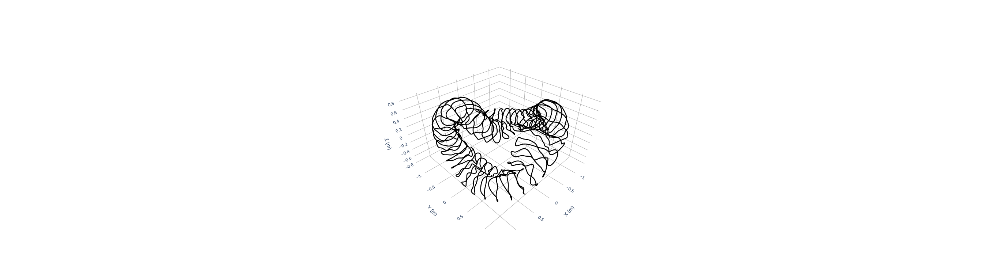

In [19]:
coilset = CoilSet.load("NFP2_A8p7_coilset_40_coils_Bn_0p015_N9.h5")
plot_coils(coilset)
#coilset

In [20]:
coilset = CoilSet.from_symmetry(
                       coilset,
                       NFP=coilset.NFP,
                       sym=coilset.sym,
                       #check_intersection=check_intersection,
                   )
#coilset.rotate(axis=[0, 0, 1.], angle=0.*np.pi/2)
#coilset.rotate(axis=[0, 0, 1.], angle=-0.0)
coilset1 = MixedCoilSet(coilset[10:30])
#coilset1.rotate(axis=[0, 0, 1.], angle=-0.02)
coilset2 = MixedCoilSet([coilset[30:], coilset[:10]])
#plot_coils(coilset2)

fig = plot_coils(coilset1)
plot_coils(coilset2, fig=fig)

In [21]:
from desc.vmec import VMECIO
eq = Equilibrium.load("eq_NFP2_A+9.0_tor+0.0_mr+0.10_shift+0.00_wd+0.00_elong+3.00_wellwt+2.0_vacuum_final2.h5")
# Equilibrium is only used to get a good guess for starting points used for fieldline tracing
# If you want to use the eq object to calculate accurate physics quantities, you need to eq.solve the equilibrium.

In [22]:
import plotly.graph_objects as go

data = eq.compute(["X", "Y", "Z"], grid=LinearGrid(rho=0., N=100, NFP=1, sym=False))

fig= plot_coils(coilset)

fig.add_scatter3d(
    x=data["X"],
    y=data["Y"],
    z=data["Z"],
    marker=dict(size=0.1,opacity=0),
    line=dict(color="black",width=6,dash="solid"),
    showlegend=False,
)
data1 = eq.compute(["X", "Y", "Z"], grid=LinearGrid(rho=0., zeta=np.pi/2-0.1, NFP=1, sym=False))

fig.add_scatter3d(
    x=data1["X"],
    y=data1["Y"],
    z=data1["Z"],
    marker=dict(size=4,opacity=1),
    line=dict(color="red",width=6,dash="solid"),
    showlegend=False,
)

data2 = eq.compute(["X", "Y", "Z"], grid=LinearGrid(rho=0., zeta=np.pi/2+0.15, NFP=1, sym=False))

fig.add_scatter3d(
    x=data2["X"],
    y=data2["Y"],
    z=data2["Z"],
    marker=dict(size=4,opacity=1),
    line=dict(color="green",width=6,dash="solid"),
    showlegend=False,
)

fig.show()

/pscratch/sd/r/rgaur/DESC2/DESC/desc/utils.py:572: UserWarning:

Unequal number of field periods for grid 1 and basis 2.

/pscratch/sd/r/rgaur/DESC2/DESC/desc/utils.py:572: UserWarning:

Unequal number of field periods for grid 1 and basis 2.

/pscratch/sd/r/rgaur/DESC2/DESC/desc/utils.py:572: UserWarning:

Unequal number of field periods for grid 1 and basis 2.

/pscratch/sd/r/rgaur/DESC2/DESC/desc/utils.py:572: UserWarning:

Unequal number of field periods for grid 1 and basis 2.

/pscratch/sd/r/rgaur/DESC2/DESC/desc/utils.py:572: UserWarning:

Unequal number of field periods for grid 1 and basis 2.

/pscratch/sd/r/rgaur/DESC2/DESC/desc/utils.py:572: UserWarning:

Unequal number of field periods for grid 1 and basis 2.



# L_over_R=0.5

In [23]:
list_new = []
for i in range(len(coilset1)):
    data = coilset1[i].compute(["X", "Y", "Z"], grid=LinearGrid(N=60))
    x_vec = np.array([data["X"] - 0.5, data["Y"], data["Z"]])
    list_new.append(FourierXYZCoil.from_values(coords=x_vec.T, N=16, current=coilset2[i].current))
    
coilset2_shifted = MixedCoilSet(list_new)

list_new = []
for i in range(len(coilset2)):
    data = coilset2[i].compute(["X", "Y", "Z"], grid=LinearGrid(N=60))
    x_vec = np.array([data["X"] + 0.5, data["Y"], data["Z"]])
    list_new.append(FourierXYZCoil.from_values(coords=x_vec.T, N=16, current=coilset1[i].current))
    
coilset1_shifted = MixedCoilSet(list_new)

#plot_coils(MixedCoilSet(coilset2_shifted, coilset1))
fig = plot_coils(coilset2_shifted)
fig = plot_coils(coilset1_shifted, fig=fig)
fig.show()

data = eq.compute(["X", "Y", "Z"], grid=LinearGrid(rho=0., zeta =np.array([np.pi/2]), NFP=1, sym=False))
data_center0 = eq.compute(["X", "Y", "Z"], grid=LinearGrid(rho=0., zeta=np.array([np.pi/2 - 0.1])))
data_center1 = eq.compute(["X", "Y", "Z"], grid=LinearGrid(rho=0., zeta=np.array([np.pi/2 + 0.1])))
normal = [data_center1["X"][0]-data_center0["X"][0]-1.0,data_center1["Y"][0]-data_center0["Y"][0],data_center1["Z"][0]-data_center0["Z"][0]]

#I = -470000
I = -510000
r_0 = 0.55

coilset3 = MixedCoilSet(
                        FourierPlanarCoil(I, center=[data["X"][0]+3/6, data_center0["Y"][0] , (3./3)*data_center0["Z"][0]], normal=normal, basis="xyz", r_n=r_0),
                        FourierPlanarCoil(I, center=[data["X"][0]-3/6, data_center1["Y"][0] , (3./3)*data_center1["Z"][0]], normal=normal, basis="xyz", r_n=r_0),
                        FourierPlanarCoil(I, center=[data["X"][0]+2/6, data_center0["Y"][0] , (2./3)*data_center0["Z"][0]], normal=normal, basis="xyz", r_n=r_0),
                        FourierPlanarCoil(I, center=[data["X"][0]-2/6, data_center1["Y"][0] , (2./3)*data_center1["Z"][0]], normal=normal, basis="xyz", r_n=r_0),
                        FourierPlanarCoil(I, center=[data["X"][0]+1/6, data_center0["Y"][0] , (1./3)*data_center0["Z"][0]], normal=normal, basis="xyz", r_n=r_0),
                        FourierPlanarCoil(I, center=[data["X"][0]-1/6, data_center1["Y"][0] , (1./3)*data_center1["Z"][0]], normal=normal, basis="xyz", r_n=r_0),
                        FourierPlanarCoil(I, center=[data["X"][0], data["Y"][0] , 0.0*data_center1["Z"][0]], normal=normal, basis="xyz", r_n=r_0),
)
#print(data_center0["Y"][0]-data["Y"][0], data_center1["Y"][0]-data["Y"][0])

data = eq.compute(["X", "Y", "Z"], grid=LinearGrid(rho=0., zeta =np.array([-1/2 * np.pi]), NFP=1, sym=False))
data_center0 = eq.compute(["X", "Y", "Z"], grid=LinearGrid(rho=0., zeta=np.array([-1 * np.pi/2 + 0.1])))
data_center1 = eq.compute(["X", "Y", "Z"], grid=LinearGrid(rho=0., zeta=np.array([-1 * np.pi/2 - 0.1])))
normal = [data_center1["X"][0]-data_center0["X"][0]-1.0,data_center1["Y"][0]-data_center0["Y"][0],data_center1["Z"][0]-data_center0["Z"][0]]

coilset4 = MixedCoilSet(FourierPlanarCoil(-I, center=[data["X"][0]+3/6, data_center0["Y"][0] , (3./3)*data_center0["Z"][0]], normal=normal, basis="xyz", r_n=r_0),
                        FourierPlanarCoil(-I, center=[data["X"][0]-3/6, data_center1["Y"][0] , (3./3)*data_center1["Z"][0]], normal=normal, basis="xyz", r_n=r_0),
                        FourierPlanarCoil(-I, center=[data["X"][0]+2/6, data_center0["Y"][0] , (2./3)*data_center0["Z"][0]], normal=normal, basis="xyz", r_n=r_0),
                        FourierPlanarCoil(-I, center=[data["X"][0]-2/6, data_center1["Y"][0] , (2./3)*data_center1["Z"][0]], normal=normal, basis="xyz", r_n=r_0),
                        FourierPlanarCoil(-I, center=[data["X"][0]+1/6, data_center0["Y"][0] , (1./3)*data_center0["Z"][0]], normal=normal, basis="xyz", r_n=r_0),
                        FourierPlanarCoil(-I, center=[data["X"][0]-1/6, data_center1["Y"][0] , (1./3)*data_center1["Z"][0]], normal=normal, basis="xyz", r_n=r_0),
                        FourierPlanarCoil(-I, center=[data["X"][0], data["Y"][0] , 0.0*data_center1["Z"][0]], normal=normal, basis="xyz", r_n=r_0),
)

#print(data_center0["Y"][0]-data["Y"][0], data_center1["Y"][0]-data["Y"][0])

#fig = plot_coils(coilset2_shifted)
#fig = plot_coils(coilset1_shifted, fig=fig)
#fig = plot_coils(coilset3, fig=fig)
#fig = plot_coils(coilset4, fig=fig)

coilset_final0 = MixedCoilSet(coilset1_shifted, coilset2_shifted, coilset3, coilset4)

fig = plot_coils(coilset_final0)
fig.show()

/pscratch/sd/r/rgaur/DESC2/DESC/desc/utils.py:572: UserWarning:

Unequal number of field periods for grid 1 and basis 2.

/pscratch/sd/r/rgaur/DESC2/DESC/desc/utils.py:572: UserWarning:

Unequal number of field periods for grid 1 and basis 2.

/pscratch/sd/r/rgaur/DESC2/DESC/desc/utils.py:572: UserWarning:

Unequal number of field periods for grid 1 and basis 2.

/pscratch/sd/r/rgaur/DESC2/DESC/desc/utils.py:572: UserWarning:

Unequal number of field periods for grid 1 and basis 2.

/pscratch/sd/r/rgaur/DESC2/DESC/desc/utils.py:572: UserWarning:

Unequal number of field periods for grid 1 and basis 2.

/pscratch/sd/r/rgaur/DESC2/DESC/desc/utils.py:572: UserWarning:

Unequal number of field periods for grid 1 and basis 2.

/pscratch/sd/r/rgaur/DESC2/DESC/desc/utils.py:572: UserWarning:

Unequal number of field periods for grid 1 and basis 2.

/pscratch/sd/r/rgaur/DESC2/DESC/desc/utils.py:572: UserWarning:

Unequal number of field periods for grid 1 and basis 2.

/pscratch/sd/r/rgaur/DES

[1.5436007  1.52816831 1.51192034 1.49465111 1.47633319 1.45730005]


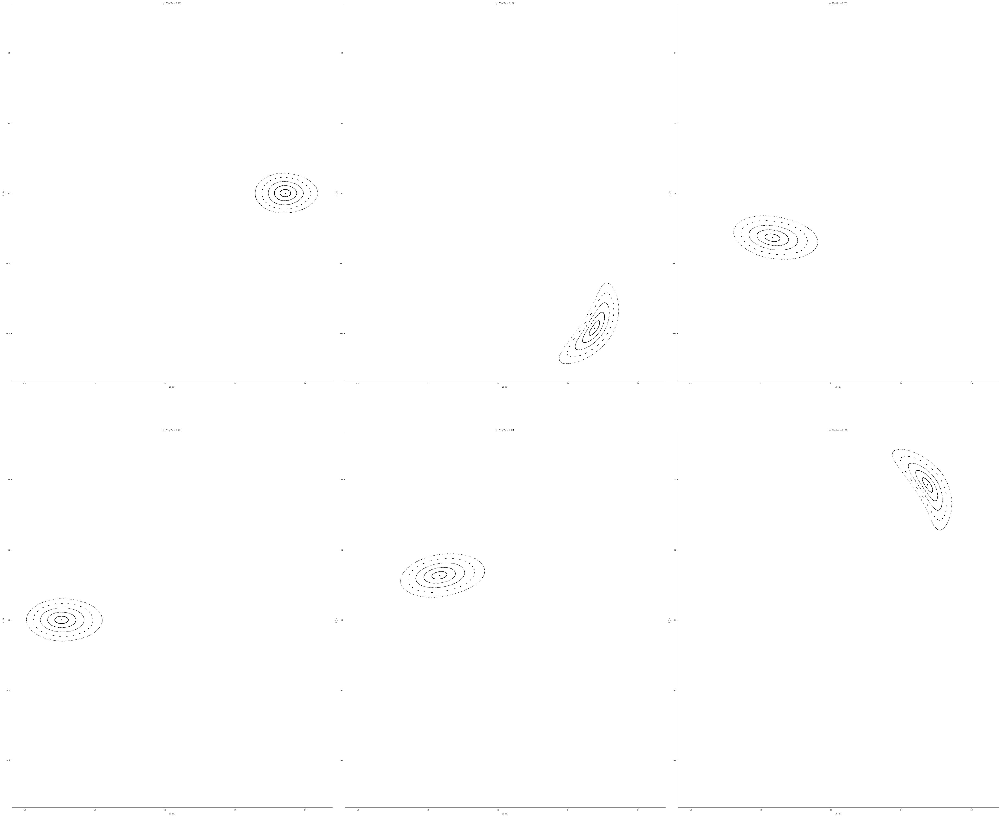

In [24]:
#plot_field_lines(surface_current_field, eq);
grid_trace = LinearGrid(rho=np.linspace(0.0, 0.7, 6))
#r0 = eq.compute("R", grid=grid_trace)["R"] + 1.084
r0 = eq.compute("R", grid=grid_trace)["R"] + 0.53
z0 = eq.compute("Z", grid=grid_trace)["Z"]
print(r0)
#fig, ax = desc.plotting.plot_surfaces(eq, figsize=(40, 40))
fig, ax, data = desc.plotting.poincare_plot(
    coilset_final0,
    r0,
    z0,
    ntransit=200,
    NFP=2,
    #ax=ax,
    color="k",
    size=1,
    return_data = True,
    bounds_R = (0.3, 2.6),
    bounds_Z = (-1, 1),
    figsize = (60, 60),
)
#fig.show()

In [12]:
#coilset_final0.save("SLNAMified_NFP2_A8p7_L_over_R_0p5_SLAM-B.h5")

# L_over_R=1.0

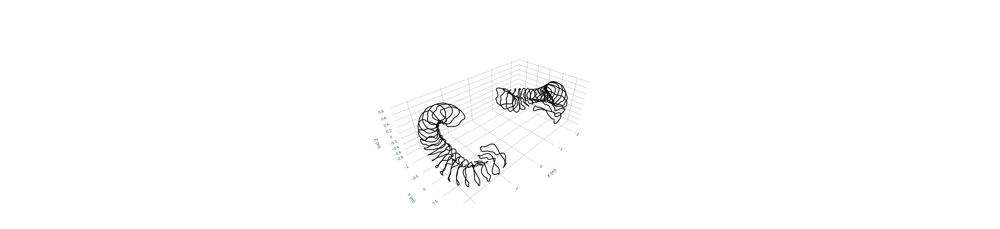

/pscratch/sd/r/rgaur/DESC2/DESC/desc/utils.py:572: UserWarning:

Unequal number of field periods for grid 1 and basis 2.

/pscratch/sd/r/rgaur/DESC2/DESC/desc/utils.py:572: UserWarning:

Unequal number of field periods for grid 1 and basis 2.

/pscratch/sd/r/rgaur/DESC2/DESC/desc/utils.py:572: UserWarning:

Unequal number of field periods for grid 1 and basis 2.

/pscratch/sd/r/rgaur/DESC2/DESC/desc/utils.py:572: UserWarning:

Unequal number of field periods for grid 1 and basis 2.

/pscratch/sd/r/rgaur/DESC2/DESC/desc/utils.py:572: UserWarning:

Unequal number of field periods for grid 1 and basis 2.

/pscratch/sd/r/rgaur/DESC2/DESC/desc/utils.py:572: UserWarning:

Unequal number of field periods for grid 1 and basis 2.

/pscratch/sd/r/rgaur/DESC2/DESC/desc/utils.py:572: UserWarning:

Unequal number of field periods for grid 1 and basis 2.

/pscratch/sd/r/rgaur/DESC2/DESC/desc/utils.py:572: UserWarning:

Unequal number of field periods for grid 1 and basis 2.

/pscratch/sd/r/rgaur/DES

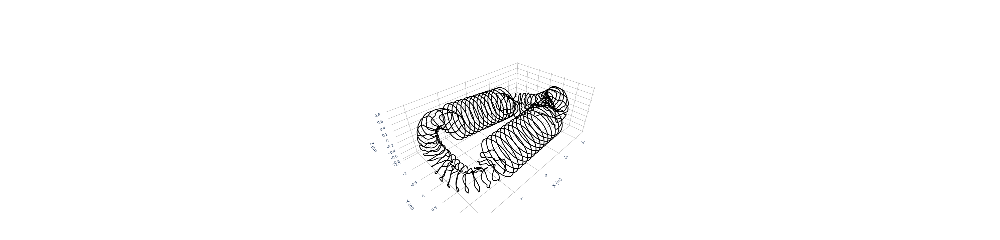

In [25]:
list_new = []
for i in range(len(coilset1)):
    data = coilset1[i].compute(["X", "Y", "Z"], grid=LinearGrid(N=60))
    x_vec = np.array([data["X"] - 1.0, data["Y"], data["Z"]])
    list_new.append(FourierXYZCoil.from_values(coords=x_vec.T, N=16, current=coilset2[i].current))
    
coilset2_shifted = MixedCoilSet(list_new)

list_new = []
for i in range(len(coilset2)):
    data = coilset2[i].compute(["X", "Y", "Z"], grid=LinearGrid(N=60))
    x_vec = np.array([data["X"] + 1.0, data["Y"], data["Z"]])
    list_new.append(FourierXYZCoil.from_values(coords=x_vec.T, N=16, current=coilset1[i].current))
    
coilset1_shifted = MixedCoilSet(list_new)

#plot_coils(MixedCoilSet(coilset2_shifted, coilset1))
fig = plot_coils(coilset2_shifted)
fig = plot_coils(coilset1_shifted, fig=fig)
fig.show()

data = eq.compute(["X", "Y", "Z"], grid=LinearGrid(rho=0., zeta =np.array([np.pi/2]), NFP=1, sym=False))
data_center0 = eq.compute(["X", "Y", "Z"], grid=LinearGrid(rho=0., zeta=np.array([np.pi/2 - 0.1])))
data_center1 = eq.compute(["X", "Y", "Z"], grid=LinearGrid(rho=0., zeta=np.array([np.pi/2 + 0.1])))
normal = [data_center1["X"][0]-data_center0["X"][0]-2.0,data_center1["Y"][0]-data_center0["Y"][0],data_center1["Z"][0]-data_center0["Z"][0]]

I = -510000
r_0 = 0.55

coilset3 = MixedCoilSet(FourierPlanarCoil(I, center=[data["X"][0]+6/6, data_center0["Y"][0] , (6./6)*data_center0["Z"][0]], normal=normal, basis="xyz", r_n=r_0),
                        FourierPlanarCoil(I, center=[data["X"][0]-6/6, data_center1["Y"][0] , (6./6)*data_center1["Z"][0]], normal=normal, basis="xyz", r_n=r_0),
                        FourierPlanarCoil(I, center=[data["X"][0]+5/6, data_center0["Y"][0] , (5./6)*data_center0["Z"][0]], normal=normal, basis="xyz", r_n=r_0),
                        FourierPlanarCoil(I, center=[data["X"][0]-5/6, data_center1["Y"][0] , (5./6)*data_center1["Z"][0]], normal=normal, basis="xyz", r_n=r_0),
                        FourierPlanarCoil(I, center=[data["X"][0]+4/6, data_center0["Y"][0] , (4./6)*data_center0["Z"][0]], normal=normal, basis="xyz", r_n=r_0),
                        FourierPlanarCoil(I, center=[data["X"][0]-4/6, data_center1["Y"][0] , (4./6)*data_center1["Z"][0]], normal=normal, basis="xyz", r_n=r_0),
                        FourierPlanarCoil(I, center=[data["X"][0]+3/6, data_center0["Y"][0] , (3./6)*data_center0["Z"][0]], normal=normal, basis="xyz", r_n=r_0),
                        FourierPlanarCoil(I, center=[data["X"][0]-3/6, data_center1["Y"][0] , (3./6)*data_center1["Z"][0]], normal=normal, basis="xyz", r_n=r_0),
                        FourierPlanarCoil(I, center=[data["X"][0]+2/6, data_center0["Y"][0] , (2./6)*data_center0["Z"][0]], normal=normal, basis="xyz", r_n=r_0),
                        FourierPlanarCoil(I, center=[data["X"][0]-2/6, data_center1["Y"][0] , (2./6)*data_center1["Z"][0]], normal=normal, basis="xyz", r_n=r_0),
                        FourierPlanarCoil(I, center=[data["X"][0]+1/6, data_center0["Y"][0] , (1./6)*data_center0["Z"][0]], normal=normal, basis="xyz", r_n=r_0),
                        FourierPlanarCoil(I, center=[data["X"][0]-1/6, data_center1["Y"][0] , (1./6)*data_center1["Z"][0]], normal=normal, basis="xyz", r_n=r_0),
                        FourierPlanarCoil(I, center=[data["X"][0], data["Y"][0] , 0.0*data_center1["Z"][0]], normal=normal, basis="xyz", r_n=r_0),
)
#print(data_center0["Y"][0]-data["Y"][0], data_center1["Y"][0]-data["Y"][0])

data = eq.compute(["X", "Y", "Z"], grid=LinearGrid(rho=0., zeta =np.array([-1/2 * np.pi]), NFP=1, sym=False))
data_center0 = eq.compute(["X", "Y", "Z"], grid=LinearGrid(rho=0., zeta=np.array([-1 * np.pi/2 + 0.1])))
data_center1 = eq.compute(["X", "Y", "Z"], grid=LinearGrid(rho=0., zeta=np.array([-1 * np.pi/2 - 0.1])))
normal = [data_center1["X"][0]-data_center0["X"][0]-2.0,data_center1["Y"][0]-data_center0["Y"][0],data_center1["Z"][0]-data_center0["Z"][0]]

coilset4 = MixedCoilSet(FourierPlanarCoil(-I, center=[data["X"][0]+6/6, data_center0["Y"][0] , (6./6)*data_center0["Z"][0]], normal=normal, basis="xyz", r_n=r_0),
                        FourierPlanarCoil(-I, center=[data["X"][0]-6/6, data_center1["Y"][0] , (6./6)*data_center1["Z"][0]], normal=normal, basis="xyz", r_n=r_0),
                        FourierPlanarCoil(-I, center=[data["X"][0]+5/6, data_center0["Y"][0] , (5./6)*data_center0["Z"][0]], normal=normal, basis="xyz", r_n=r_0),
                        FourierPlanarCoil(-I, center=[data["X"][0]-5/6, data_center1["Y"][0] , (5./6)*data_center1["Z"][0]], normal=normal, basis="xyz", r_n=r_0),
                        FourierPlanarCoil(-I, center=[data["X"][0]+4/6, data_center0["Y"][0] , (4./6)*data_center0["Z"][0]], normal=normal, basis="xyz", r_n=r_0),
                        FourierPlanarCoil(-I, center=[data["X"][0]-4/6, data_center1["Y"][0] , (4./6)*data_center1["Z"][0]], normal=normal, basis="xyz", r_n=r_0),
                        FourierPlanarCoil(-I, center=[data["X"][0]+3/6, data_center0["Y"][0] , (3./6)*data_center0["Z"][0]], normal=normal, basis="xyz", r_n=r_0),
                        FourierPlanarCoil(-I, center=[data["X"][0]-3/6, data_center1["Y"][0] , (3./6)*data_center1["Z"][0]], normal=normal, basis="xyz", r_n=r_0),
                        FourierPlanarCoil(-I, center=[data["X"][0]+2/6, data_center0["Y"][0] , (2./6)*data_center0["Z"][0]], normal=normal, basis="xyz", r_n=r_0),
                        FourierPlanarCoil(-I, center=[data["X"][0]-2/6, data_center1["Y"][0] , (2./6)*data_center1["Z"][0]], normal=normal, basis="xyz", r_n=r_0),
                        FourierPlanarCoil(-I, center=[data["X"][0]+1/6, data_center0["Y"][0] , (1./6)*data_center0["Z"][0]], normal=normal, basis="xyz", r_n=r_0),
                        FourierPlanarCoil(-I, center=[data["X"][0]-1/6, data_center1["Y"][0] , (1./6)*data_center1["Z"][0]], normal=normal, basis="xyz", r_n=r_0),
                        FourierPlanarCoil(-I, center=[data["X"][0], data["Y"][0] , 0.0*data_center1["Z"][0]], normal=normal, basis="xyz", r_n=r_0),
)

#print(data_center0["Y"][0]-data["Y"][0], data_center1["Y"][0]-data["Y"][0])

#fig = plot_coils(coilset2_shifted)
#fig = plot_coils(coilset1_shifted, fig=fig)
#fig = plot_coils(coilset3, fig=fig)
#fig = plot_coils(coilset4, fig=fig)

coilset_final1 = MixedCoilSet(coilset1_shifted, coilset2_shifted, coilset3, coilset4)

fig = plot_coils(coilset_final1)
fig.show()

[2.0286007  1.99451903 1.95594035 1.91594288]


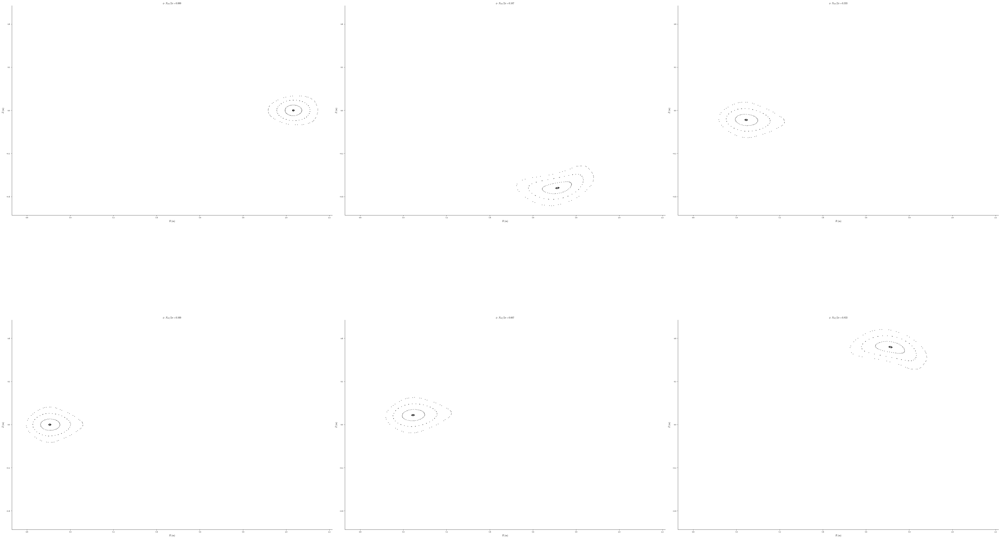

In [26]:
#plot_field_lines(surface_current_field, eq);
grid_trace = LinearGrid(rho=np.linspace(0.0, 0.9, 4))
#r0 = eq.compute("R", grid=grid_trace)["R"] + 1.084
r0 = eq.compute("R", grid=grid_trace)["R"] + 1.015
z0 = eq.compute("Z", grid=grid_trace)["Z"]
print(r0)
#fig, ax = desc.plotting.plot_surfaces(eq, figsize=(40, 40))
fig, ax, data = desc.plotting.poincare_plot(
    coilset_final1,
    r0,
    z0,
    ntransit=50,
    NFP=2,
    #ax=ax,
    color="k",
    size=1,
    return_data = True,
    bounds_R = (0.3, 2.6),
    bounds_Z = (-1, 1),
    figsize = (60, 60),
)
#fig.show()

In [27]:
coilset_final1.save("SLNAMified_NFP2_A8p7_L_over_R_1p0_SLAM-A.h5")

# L_over_R = 1.5

In [25]:
list_new = []
for i in range(len(coilset1)):
    data = coilset1[i].compute(["X", "Y", "Z"], grid=LinearGrid(N=60))
    x_vec = np.array([data["X"] - 1.5, data["Y"], data["Z"]])
    list_new.append(FourierXYZCoil.from_values(coords=x_vec.T, N=16, current=coilset2[i].current))
    
coilset2_shifted = MixedCoilSet(list_new)

list_new = []
for i in range(len(coilset2)):
    data = coilset2[i].compute(["X", "Y", "Z"], grid=LinearGrid(N=60))
    x_vec = np.array([data["X"] + 1.5, data["Y"], data["Z"]])
    list_new.append(FourierXYZCoil.from_values(coords=x_vec.T, N=16, current=coilset1[i].current))
    
coilset1_shifted = MixedCoilSet(list_new)
#plot_field_lines(surface_current_field, eq)
#plot_coils(MixedCoilSet(coilset2_shifted, coilset1))
fig = plot_coils(coilset2_shifted)
fig = plot_coils(coilset1_shifted, fig=fig)
fig.show()


data = eq.compute(["X", "Y", "Z"], grid=LinearGrid(rho=0., zeta =np.array([np.pi/2]), NFP=1, sym=False))
data_center0 = eq.compute(["X", "Y", "Z"], grid=LinearGrid(rho=0., zeta=np.array([np.pi/2 - 0.1])))
data_center1 = eq.compute(["X", "Y", "Z"], grid=LinearGrid(rho=0., zeta=np.array([np.pi/2 + 0.1])))
normal = [data_center1["X"][0]-data_center0["X"][0]-3,data_center1["Y"][0]-data_center0["Y"][0],data_center1["Z"][0]-data_center0["Z"][0]]

I = -510000
r_0 = 0.55

coilset3 = MixedCoilSet(
                        FourierPlanarCoil(I, center=[data["X"][0]+9/6, data_center0["Y"][0] , (9./9)*data_center0["Z"][0]], normal=normal, basis="xyz", r_n=r_0),
                        FourierPlanarCoil(I, center=[data["X"][0]-9/6, data_center1["Y"][0] , (9./9)*data_center1["Z"][0]], normal=normal, basis="xyz", r_n=r_0),
                        FourierPlanarCoil(I, center=[data["X"][0]+8/6, data_center0["Y"][0] , (8./9)*data_center0["Z"][0]], normal=normal, basis="xyz", r_n=r_0),
                        FourierPlanarCoil(I, center=[data["X"][0]-8/6, data_center1["Y"][0] , (8./9)*data_center1["Z"][0]], normal=normal, basis="xyz", r_n=r_0),
                        FourierPlanarCoil(I, center=[data["X"][0]+7/6, data_center0["Y"][0] , (7./9)*data_center0["Z"][0]], normal=normal, basis="xyz", r_n=r_0),
                        FourierPlanarCoil(I, center=[data["X"][0]-7/6, data_center1["Y"][0] , (7./9)*data_center1["Z"][0]], normal=normal, basis="xyz", r_n=r_0),
                        FourierPlanarCoil(I, center=[data["X"][0]+6/6, data_center0["Y"][0] , (6./9)*data_center0["Z"][0]], normal=normal, basis="xyz", r_n=r_0),
                        FourierPlanarCoil(I, center=[data["X"][0]-6/6, data_center1["Y"][0] , (6./9)*data_center1["Z"][0]], normal=normal, basis="xyz", r_n=r_0),
                        FourierPlanarCoil(I, center=[data["X"][0]+5/6, data_center0["Y"][0] , (5./9)*data_center0["Z"][0]], normal=normal, basis="xyz", r_n=r_0),
                        FourierPlanarCoil(I, center=[data["X"][0]-5/6, data_center1["Y"][0] , (5./9)*data_center1["Z"][0]], normal=normal, basis="xyz", r_n=r_0),
                        FourierPlanarCoil(I, center=[data["X"][0]+4/6, data_center0["Y"][0] , (4./9)*data_center0["Z"][0]], normal=normal, basis="xyz", r_n=r_0),
                        FourierPlanarCoil(I, center=[data["X"][0]-4/6, data_center1["Y"][0] , (4./9)*data_center1["Z"][0]], normal=normal, basis="xyz", r_n=r_0),
                        FourierPlanarCoil(I, center=[data["X"][0]+3/6, data_center0["Y"][0] , (3./9)*data_center0["Z"][0]], normal=normal, basis="xyz", r_n=r_0),
                        FourierPlanarCoil(I, center=[data["X"][0]-3/6, data_center1["Y"][0] , (3./9)*data_center1["Z"][0]], normal=normal, basis="xyz", r_n=r_0),
                        FourierPlanarCoil(I, center=[data["X"][0]+2/6, data_center0["Y"][0] , (2./9)*data_center0["Z"][0]], normal=normal, basis="xyz", r_n=r_0),
                        FourierPlanarCoil(I, center=[data["X"][0]-2/6, data_center1["Y"][0] , (2./9)*data_center1["Z"][0]], normal=normal, basis="xyz", r_n=r_0),
                        FourierPlanarCoil(I, center=[data["X"][0]+1/6, data_center0["Y"][0] , (1./9)*data_center0["Z"][0]], normal=normal, basis="xyz", r_n=r_0),
                        FourierPlanarCoil(I, center=[data["X"][0]-1/6, data_center1["Y"][0] , (1./9)*data_center1["Z"][0]], normal=normal, basis="xyz", r_n=r_0),
                        FourierPlanarCoil(I, center=[data["X"][0], data["Y"][0] , 0.0*data_center1["Z"][0]], normal=normal, basis="xyz", r_n=r_0),
)
#print(data_center0["Y"][0]-data["Y"][0], data_center1["Y"][0]-data["Y"][0])

data = eq.compute(["X", "Y", "Z"], grid=LinearGrid(rho=0., zeta =np.array([-1/2 * np.pi]), NFP=1, sym=False))
data_center0 = eq.compute(["X", "Y", "Z"], grid=LinearGrid(rho=0., zeta=np.array([-1 * np.pi/2 + 0.1])))
data_center1 = eq.compute(["X", "Y", "Z"], grid=LinearGrid(rho=0., zeta=np.array([-1 * np.pi/2 - 0.1])))
normal = [data_center1["X"][0]-data_center0["X"][0]-3,data_center1["Y"][0]-data_center0["Y"][0],data_center1["Z"][0]-data_center0["Z"][0]]

coilset4 = MixedCoilSet(
                        FourierPlanarCoil(-I, center=[data["X"][0]+9/6, data_center0["Y"][0] , (9./9)*data_center0["Z"][0]], normal=normal, basis="xyz", r_n=r_0),
                        FourierPlanarCoil(-I, center=[data["X"][0]-9/6, data_center1["Y"][0] , (9./9)*data_center1["Z"][0]], normal=normal, basis="xyz", r_n=r_0),
                        FourierPlanarCoil(-I, center=[data["X"][0]+8/6, data_center0["Y"][0] , (8./9)*data_center0["Z"][0]], normal=normal, basis="xyz", r_n=r_0),
                        FourierPlanarCoil(-I, center=[data["X"][0]-8/6, data_center1["Y"][0] , (8./9)*data_center1["Z"][0]], normal=normal, basis="xyz", r_n=r_0),
                        FourierPlanarCoil(-I, center=[data["X"][0]+7/6, data_center0["Y"][0] , (7./9)*data_center0["Z"][0]], normal=normal, basis="xyz", r_n=r_0),
                        FourierPlanarCoil(-I, center=[data["X"][0]-7/6, data_center1["Y"][0] , (7./9)*data_center1["Z"][0]], normal=normal, basis="xyz", r_n=r_0),
                        FourierPlanarCoil(-I, center=[data["X"][0]+6/6, data_center0["Y"][0] , (6./9)*data_center0["Z"][0]], normal=normal, basis="xyz", r_n=r_0),
                        FourierPlanarCoil(-I, center=[data["X"][0]-6/6, data_center1["Y"][0] , (6./9)*data_center1["Z"][0]], normal=normal, basis="xyz", r_n=r_0),
                        FourierPlanarCoil(-I, center=[data["X"][0]+5/6, data_center0["Y"][0] , (5./9)*data_center0["Z"][0]], normal=normal, basis="xyz", r_n=r_0),
                        FourierPlanarCoil(-I, center=[data["X"][0]-5/6, data_center1["Y"][0] , (5./9)*data_center1["Z"][0]], normal=normal, basis="xyz", r_n=r_0),
                        FourierPlanarCoil(-I, center=[data["X"][0]+4/6, data_center0["Y"][0] , (4./9)*data_center0["Z"][0]], normal=normal, basis="xyz", r_n=r_0),
                        FourierPlanarCoil(-I, center=[data["X"][0]-4/6, data_center1["Y"][0] , (4./9)*data_center1["Z"][0]], normal=normal, basis="xyz", r_n=r_0),
                        FourierPlanarCoil(-I, center=[data["X"][0]+3/6, data_center0["Y"][0] , (3./9)*data_center0["Z"][0]], normal=normal, basis="xyz", r_n=r_0),
                        FourierPlanarCoil(-I, center=[data["X"][0]-3/6, data_center1["Y"][0] , (3./9)*data_center1["Z"][0]], normal=normal, basis="xyz", r_n=r_0),
                        FourierPlanarCoil(-I, center=[data["X"][0]+2/6, data_center0["Y"][0] , (2./9)*data_center0["Z"][0]], normal=normal, basis="xyz", r_n=r_0),
                        FourierPlanarCoil(-I, center=[data["X"][0]-2/6, data_center1["Y"][0] , (2./9)*data_center1["Z"][0]], normal=normal, basis="xyz", r_n=r_0),
                        FourierPlanarCoil(-I, center=[data["X"][0]+1/6, data_center0["Y"][0] , (1./9)*data_center0["Z"][0]], normal=normal, basis="xyz", r_n=r_0),
                        FourierPlanarCoil(-I, center=[data["X"][0]-1/6, data_center1["Y"][0] , (1./9)*data_center1["Z"][0]], normal=normal, basis="xyz", r_n=r_0),
                        FourierPlanarCoil(-I, center=[data["X"][0], data["Y"][0] , 0.0*data_center1["Z"][0]], normal=normal, basis="xyz", r_n=r_0),
)
#print(data_center0["Y"][0]-data["Y"][0], data_center1["Y"][0]-data["Y"][0])

#fig = plot_coils(coilset2_shifted)
#fig = plot_coils(coilset1_shifted, fig=fig)
#fig = plot_coils(coilset3, fig=fig)
#fig = plot_coils(coilset4, fig=fig)

coilset_final2 = MixedCoilSet(coilset1_shifted, coilset2_shifted, coilset3, coilset4)

fig = plot_coils(coilset_final2)
fig.show()

/pscratch/sd/r/rgaur/DESC2/DESC/desc/utils.py:572: UserWarning:

Unequal number of field periods for grid 1 and basis 2.

/pscratch/sd/r/rgaur/DESC2/DESC/desc/utils.py:572: UserWarning:

Unequal number of field periods for grid 1 and basis 2.

/pscratch/sd/r/rgaur/DESC2/DESC/desc/utils.py:572: UserWarning:

Unequal number of field periods for grid 1 and basis 2.

/pscratch/sd/r/rgaur/DESC2/DESC/desc/utils.py:572: UserWarning:

Unequal number of field periods for grid 1 and basis 2.

/pscratch/sd/r/rgaur/DESC2/DESC/desc/utils.py:572: UserWarning:

Unequal number of field periods for grid 1 and basis 2.

/pscratch/sd/r/rgaur/DESC2/DESC/desc/utils.py:572: UserWarning:

Unequal number of field periods for grid 1 and basis 2.

/pscratch/sd/r/rgaur/DESC2/DESC/desc/utils.py:572: UserWarning:

Unequal number of field periods for grid 1 and basis 2.

/pscratch/sd/r/rgaur/DESC2/DESC/desc/utils.py:572: UserWarning:

Unequal number of field periods for grid 1 and basis 2.

/pscratch/sd/r/rgaur/DES

[2.5386007  2.50451903 2.46594035 2.42594288]


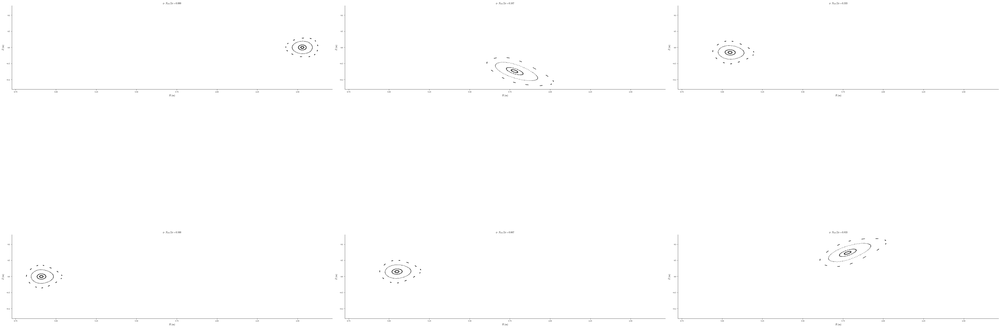

In [27]:
#plot_field_lines(surface_current_field, eq);
grid_trace = LinearGrid(rho=np.linspace(0.0, 0.9, 4))
#r0 = eq.compute("R", grid=grid_trace)["R"] + 1.084
r0 = eq.compute("R", grid=grid_trace)["R"] + 1.525
z0 = eq.compute("Z", grid=grid_trace)["Z"]
print(r0)
#fig, ax = desc.plotting.plot_surfaces(eq, figsize=(40, 40))
fig, ax, data = desc.plotting.poincare_plot(
    coilset_final2,
    r0,
    z0,
    ntransit=100,
    NFP=2,
    #ax=ax,
    color="k",
    size=1,
    return_data = True,
    bounds_R = (0.3, 3.5),
    bounds_Z = (-1, 1),
    figsize = (60, 60),
)

In [23]:
coilset_final2.save("SLNAMified_NFP2_A8p7_L_over_R_1p5_SLAM-B.h5")

# L_over_R = 2

In [28]:
list_new = []
for i in range(len(coilset1)):
    data = coilset1[i].compute(["X", "Y", "Z"], grid=LinearGrid(N=60))
    x_vec = np.array([data["X"] - 2.0, data["Y"], data["Z"]])
    list_new.append(FourierXYZCoil.from_values(coords=x_vec.T, N=16, current=coilset2[i].current))
    
coilset2_shifted = MixedCoilSet(list_new)

list_new = []
for i in range(len(coilset2)):
    data = coilset2[i].compute(["X", "Y", "Z"], grid=LinearGrid(N=60))
    x_vec = np.array([data["X"] + 2.0, data["Y"], data["Z"]])
    list_new.append(FourierXYZCoil.from_values(coords=x_vec.T, N=16, current=coilset1[i].current))
    
coilset1_shifted = MixedCoilSet(list_new)
#plot_field_lines(surface_current_field, eq)
#plot_coils(MixedCoilSet(coilset2_shifted, coilset1))
fig = plot_coils(coilset2_shifted)
fig = plot_coils(coilset1_shifted, fig=fig)
fig.show()


data = eq.compute(["X", "Y", "Z"], grid=LinearGrid(rho=0., zeta =np.array([np.pi/2]), NFP=1, sym=False))
data_center0 = eq.compute(["X", "Y", "Z"], grid=LinearGrid(rho=0., zeta=np.array([np.pi/2 - 0.1])))
data_center1 = eq.compute(["X", "Y", "Z"], grid=LinearGrid(rho=0., zeta=np.array([np.pi/2 + 0.1])))
normal = [data_center1["X"][0]-data_center0["X"][0]-4.0,data_center1["Y"][0]-data_center0["Y"][0],data_center1["Z"][0]-data_center0["Z"][0]]

I = -510000
r_0 = 0.55

coilset3 = MixedCoilSet(FourierPlanarCoil(I, center=[data["X"][0]+12/6, data_center0["Y"][0] , (12./12)*data_center0["Z"][0]], normal=normal, basis="xyz", r_n=r_0),
                        FourierPlanarCoil(I, center=[data["X"][0]-12/6, data_center1["Y"][0] , (12./12)*data_center1["Z"][0]], normal=normal, basis="xyz", r_n=r_0),
                        FourierPlanarCoil(I, center=[data["X"][0]+11/6, data_center0["Y"][0] , (11./12)*data_center0["Z"][0]], normal=normal, basis="xyz", r_n=r_0),
                        FourierPlanarCoil(I, center=[data["X"][0]-11/6, data_center1["Y"][0] , (11./12)*data_center1["Z"][0]], normal=normal, basis="xyz", r_n=r_0),
                        FourierPlanarCoil(I, center=[data["X"][0]+10/6, data_center0["Y"][0] , (10./12)*data_center0["Z"][0]], normal=normal, basis="xyz", r_n=r_0),
                        FourierPlanarCoil(I, center=[data["X"][0]-10/6, data_center1["Y"][0] , (10./12)*data_center1["Z"][0]], normal=normal, basis="xyz", r_n=r_0),
                        FourierPlanarCoil(I, center=[data["X"][0]+9/6, data_center0["Y"][0] , (9./12)*data_center0["Z"][0]], normal=normal, basis="xyz", r_n=r_0),
                        FourierPlanarCoil(I, center=[data["X"][0]-9/6, data_center1["Y"][0] , (9./12)*data_center1["Z"][0]], normal=normal, basis="xyz", r_n=r_0),
                        FourierPlanarCoil(I, center=[data["X"][0]+8/6, data_center0["Y"][0] , (8./12)*data_center0["Z"][0]], normal=normal, basis="xyz", r_n=r_0),
                        FourierPlanarCoil(I, center=[data["X"][0]-8/6, data_center1["Y"][0] , (8./12)*data_center1["Z"][0]], normal=normal, basis="xyz", r_n=r_0),
                        FourierPlanarCoil(I, center=[data["X"][0]+7/6, data_center0["Y"][0] , (7./12)*data_center0["Z"][0]], normal=normal, basis="xyz", r_n=r_0),
                        FourierPlanarCoil(I, center=[data["X"][0]-7/6, data_center1["Y"][0] , (7./12)*data_center1["Z"][0]], normal=normal, basis="xyz", r_n=r_0),
                        FourierPlanarCoil(I, center=[data["X"][0]+6/6, data_center0["Y"][0] , (6./12)*data_center0["Z"][0]], normal=normal, basis="xyz", r_n=r_0),
                        FourierPlanarCoil(I, center=[data["X"][0]-6/6, data_center1["Y"][0] , (6./12)*data_center1["Z"][0]], normal=normal, basis="xyz", r_n=r_0),
                        FourierPlanarCoil(I, center=[data["X"][0]+5/6, data_center0["Y"][0] , (5./12)*data_center0["Z"][0]], normal=normal, basis="xyz", r_n=r_0),
                        FourierPlanarCoil(I, center=[data["X"][0]-5/6, data_center1["Y"][0] , (5./12)*data_center1["Z"][0]], normal=normal, basis="xyz", r_n=r_0),
                        FourierPlanarCoil(I, center=[data["X"][0]+4/6, data_center0["Y"][0] , (4./12)*data_center0["Z"][0]], normal=normal, basis="xyz", r_n=r_0),
                        FourierPlanarCoil(I, center=[data["X"][0]-4/6, data_center1["Y"][0] , (4./12)*data_center1["Z"][0]], normal=normal, basis="xyz", r_n=r_0),
                        FourierPlanarCoil(I, center=[data["X"][0]+3/6, data_center0["Y"][0] , (3./12)*data_center0["Z"][0]], normal=normal, basis="xyz", r_n=r_0),
                        FourierPlanarCoil(I, center=[data["X"][0]-3/6, data_center1["Y"][0] , (3./12)*data_center1["Z"][0]], normal=normal, basis="xyz", r_n=r_0),
                        FourierPlanarCoil(I, center=[data["X"][0]+2/6, data_center0["Y"][0] , (2./12)*data_center0["Z"][0]], normal=normal, basis="xyz", r_n=r_0),
                        FourierPlanarCoil(I, center=[data["X"][0]-2/6, data_center1["Y"][0] , (2./12)*data_center1["Z"][0]], normal=normal, basis="xyz", r_n=r_0),
                        FourierPlanarCoil(I, center=[data["X"][0]+1/6, data_center0["Y"][0] , (1./12)*data_center0["Z"][0]], normal=normal, basis="xyz", r_n=r_0),
                        FourierPlanarCoil(I, center=[data["X"][0]-1/6, data_center1["Y"][0] , (1./12)*data_center1["Z"][0]], normal=normal, basis="xyz", r_n=r_0),
                        FourierPlanarCoil(I, center=[data["X"][0], data["Y"][0] , 0.0*data_center1["Z"][0]], normal=normal, basis="xyz", r_n=r_0),
)
#print(data_center0["Y"][0]-data["Y"][0], data_center1["Y"][0]-data["Y"][0])

data = eq.compute(["X", "Y", "Z"], grid=LinearGrid(rho=0., zeta =np.array([-1/2 * np.pi]), NFP=1, sym=False))
data_center0 = eq.compute(["X", "Y", "Z"], grid=LinearGrid(rho=0., zeta=np.array([-1 * np.pi/2 + 0.1])))
data_center1 = eq.compute(["X", "Y", "Z"], grid=LinearGrid(rho=0., zeta=np.array([-1 * np.pi/2 - 0.1])))
normal = [data_center1["X"][0]-data_center0["X"][0]-4.0,data_center1["Y"][0]-data_center0["Y"][0],data_center1["Z"][0]-data_center0["Z"][0]]

coilset4 = MixedCoilSet(FourierPlanarCoil(-I, center=[data["X"][0]+12/6, data_center0["Y"][0] , (12./12)*data_center0["Z"][0]], normal=normal, basis="xyz", r_n=r_0),
                        FourierPlanarCoil(-I, center=[data["X"][0]-12/6, data_center1["Y"][0] , (12./12)*data_center1["Z"][0]], normal=normal, basis="xyz", r_n=r_0),
                        FourierPlanarCoil(-I, center=[data["X"][0]+11/6, data_center0["Y"][0] , (11./12)*data_center0["Z"][0]], normal=normal, basis="xyz", r_n=r_0),
                        FourierPlanarCoil(-I, center=[data["X"][0]-11/6, data_center1["Y"][0] , (11./12)*data_center1["Z"][0]], normal=normal, basis="xyz", r_n=r_0),
                        FourierPlanarCoil(-I, center=[data["X"][0]+10/6, data_center0["Y"][0] , (10./12)*data_center0["Z"][0]], normal=normal, basis="xyz", r_n=r_0),
                        FourierPlanarCoil(-I, center=[data["X"][0]-10/6, data_center1["Y"][0] , (10./12)*data_center1["Z"][0]], normal=normal, basis="xyz", r_n=r_0),
                        FourierPlanarCoil(-I, center=[data["X"][0]+9/6, data_center0["Y"][0] , (9./12)*data_center0["Z"][0]], normal=normal, basis="xyz", r_n=r_0),
                        FourierPlanarCoil(-I, center=[data["X"][0]-9/6, data_center1["Y"][0] , (9./12)*data_center1["Z"][0]], normal=normal, basis="xyz", r_n=r_0),
                        FourierPlanarCoil(-I, center=[data["X"][0]+8/6, data_center0["Y"][0] , (8./12)*data_center0["Z"][0]], normal=normal, basis="xyz", r_n=r_0),
                        FourierPlanarCoil(-I, center=[data["X"][0]-8/6, data_center1["Y"][0] , (8./12)*data_center1["Z"][0]], normal=normal, basis="xyz", r_n=r_0),
                        FourierPlanarCoil(-I, center=[data["X"][0]+7/6, data_center0["Y"][0] , (7./12)*data_center0["Z"][0]], normal=normal, basis="xyz", r_n=r_0),
                        FourierPlanarCoil(-I, center=[data["X"][0]-7/6, data_center1["Y"][0] , (7./12)*data_center1["Z"][0]], normal=normal, basis="xyz", r_n=r_0),
                        FourierPlanarCoil(-I, center=[data["X"][0]+6/6, data_center0["Y"][0] , (6./12)*data_center0["Z"][0]], normal=normal, basis="xyz", r_n=r_0),
                        FourierPlanarCoil(-I, center=[data["X"][0]-6/6, data_center1["Y"][0] , (6./12)*data_center1["Z"][0]], normal=normal, basis="xyz", r_n=r_0),
                        FourierPlanarCoil(-I, center=[data["X"][0]+5/6, data_center0["Y"][0] , (5./12)*data_center0["Z"][0]], normal=normal, basis="xyz", r_n=r_0),
                        FourierPlanarCoil(-I, center=[data["X"][0]-5/6, data_center1["Y"][0] , (5./12)*data_center1["Z"][0]], normal=normal, basis="xyz", r_n=r_0),
                        FourierPlanarCoil(-I, center=[data["X"][0]+4/6, data_center0["Y"][0] , (4./12)*data_center0["Z"][0]], normal=normal, basis="xyz", r_n=r_0),
                        FourierPlanarCoil(-I, center=[data["X"][0]-4/6, data_center1["Y"][0] , (4./12)*data_center1["Z"][0]], normal=normal, basis="xyz", r_n=r_0),
                        FourierPlanarCoil(-I, center=[data["X"][0]+3/6, data_center0["Y"][0] , (3./12)*data_center0["Z"][0]], normal=normal, basis="xyz", r_n=r_0),
                        FourierPlanarCoil(-I, center=[data["X"][0]-3/6, data_center1["Y"][0] , (3./12)*data_center1["Z"][0]], normal=normal, basis="xyz", r_n=r_0),
                        FourierPlanarCoil(-I, center=[data["X"][0]+2/6, data_center0["Y"][0] , (2./12)*data_center0["Z"][0]], normal=normal, basis="xyz", r_n=r_0),
                        FourierPlanarCoil(-I, center=[data["X"][0]-2/6, data_center1["Y"][0] , (2./12)*data_center1["Z"][0]], normal=normal, basis="xyz", r_n=r_0),
                        FourierPlanarCoil(-I, center=[data["X"][0]+1/6, data_center0["Y"][0] , (1./12)*data_center0["Z"][0]], normal=normal, basis="xyz", r_n=r_0),
                        FourierPlanarCoil(-I, center=[data["X"][0]-1/6, data_center1["Y"][0] , (1./12)*data_center1["Z"][0]], normal=normal, basis="xyz", r_n=r_0),
                        FourierPlanarCoil(-I, center=[data["X"][0], data["Y"][0] , 0.0*data_center1["Z"][0]], normal=normal, basis="xyz", r_n=r_0),
)
#print(data_center0["Y"][0]-data["Y"][0], data_center1["Y"][0]-data["Y"][0])

#fig = plot_coils(coilset2_shifted)
#fig = plot_coils(coilset1_shifted, fig=fig)
#fig = plot_coils(coilset3, fig=fig)
#fig = plot_coils(coilset4, fig=fig)

coilset_final3 = MixedCoilSet(coilset1_shifted, coilset2_shifted, coilset3, coilset4)

fig = plot_coils(coilset_final3)
fig.show()

/pscratch/sd/r/rgaur/DESC2/DESC/desc/utils.py:572: UserWarning:

Unequal number of field periods for grid 1 and basis 2.

/pscratch/sd/r/rgaur/DESC2/DESC/desc/utils.py:572: UserWarning:

Unequal number of field periods for grid 1 and basis 2.

/pscratch/sd/r/rgaur/DESC2/DESC/desc/utils.py:572: UserWarning:

Unequal number of field periods for grid 1 and basis 2.

/pscratch/sd/r/rgaur/DESC2/DESC/desc/utils.py:572: UserWarning:

Unequal number of field periods for grid 1 and basis 2.

/pscratch/sd/r/rgaur/DESC2/DESC/desc/utils.py:572: UserWarning:

Unequal number of field periods for grid 1 and basis 2.

/pscratch/sd/r/rgaur/DESC2/DESC/desc/utils.py:572: UserWarning:

Unequal number of field periods for grid 1 and basis 2.

/pscratch/sd/r/rgaur/DESC2/DESC/desc/utils.py:572: UserWarning:

Unequal number of field periods for grid 1 and basis 2.

/pscratch/sd/r/rgaur/DESC2/DESC/desc/utils.py:572: UserWarning:

Unequal number of field periods for grid 1 and basis 2.

/pscratch/sd/r/rgaur/DES

[3.0236007  3.002932   2.98069405 2.95660131 2.93130134 2.90734994]


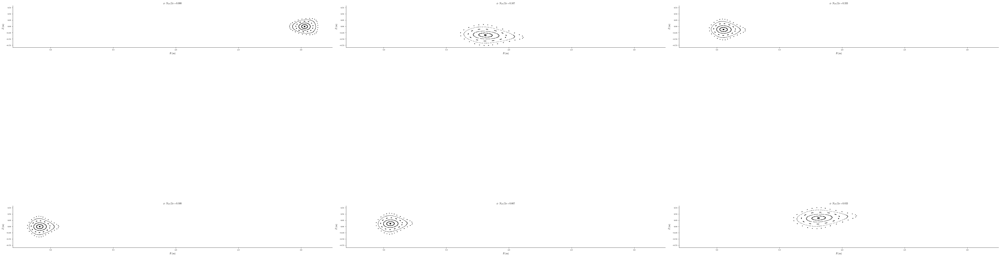

In [20]:
#plot_field_lines(surface_current_field, eq);
grid_trace = LinearGrid(rho=np.linspace(0.0, 0.93, 6))
#r0 = eq.compute("R", grid=grid_trace)["R"] + 1.084
r0 = eq.compute("R", grid=grid_trace)["R"] + 2.01
z0 = eq.compute("Z", grid=grid_trace)["Z"]
print(r0)
#fig, ax = desc.plotting.plot_surfaces(eq, figsize=(40, 40))
fig, ax, data = desc.plotting.poincare_plot(
    coilset_final3,
    r0,
    z0,
    ntransit=100,
    NFP=2,
    #ax=ax,
    color="k",
    size=1,
    return_data = True,
    bounds_R = (0.3, 4.0),
    bounds_Z = (-1, 1),
    figsize = (60, 60),
)

In [24]:
coilset_final3.save("SLNAMified_NFP2_A8p7_L_over_R_2p0_SLAM-B.h5")